# Model 2: Brain MRI classification with GLCM + Wavelets → Random Forest

**GLCM:** Gray-Level Co-occurrence Matrix. **DWT:** Discrete Wavelet Transform. **RF:** Random Forest. This is a tumor/no-tumor (or multiclass) **classification** baseline, not a segmentation system or clinical diagnostic tool.

Create `data/manifest.csv` with columns `image_path,label,patient_id`. Image paths are relative to `data/` (or absolute). Example: `tumor/p01_01.png,tumor,p01`. **Use genuine patient IDs** when multiple MRI slices belong to the same patient. Patient-wise splits prevent data leakage. Do not infer IDs from filenames without checking metadata.

If using the 12K brain MRI dataset, inspect its licensing, label definitions, masks and patient identifiers before building the manifest. If patient IDs are unavailable, the notebook intentionally stops unless you explicitly permit image-level splitting (which is less reliable).

In [6]:
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, pywt, joblib
from PIL import Image
from skimage import exposure, transform
from skimage.feature import graycomatrix, graycoprops
from sklearn.model_selection import (
    GroupShuffleSplit, train_test_split,
    StratifiedGroupKFold, StratifiedKFold, RandomizedSearchCV
)
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report, ConfusionMatrixDisplay,
    balanced_accuracy_score, roc_auc_score,
    accuracy_score, f1_score
)
from sklearn.inspection import permutation_importance

# Reproducibility
SEED = 42

# Current notebook directory
PROJECT_DIR = Path.cwd()

# Existing Brain Tumor 12K MRI dataset
DATA_ROOT = (
    PROJECT_DIR
    / ".."
    / ".."
    / ".."
    / "Datasets"
    / "Brain Tumor 12K Mri Images"
).resolve()

# Manifest file stored locally in Model 2
MANIFEST = PROJECT_DIR / "data" / "manifest.csv"
MANIFEST.parent.mkdir(parents=True, exist_ok=True)

# Model outputs
OUT = Path("outputs/model2")
OUT.mkdir(parents=True, exist_ok=True)

# Model configuration
ALLOW_IMAGE_LEVEL_SPLIT = False
IMAGE_SIZE = (224, 224)

# Verify paths
print("Working directory:", PROJECT_DIR)
print("Dataset directory:", DATA_ROOT)
print("Dataset exists:", DATA_ROOT.exists())
print("Manifest path:", MANIFEST)
print("Manifest exists:", MANIFEST.exists())

Working directory: c:\Users\fgmam\Documents\GitHub\Medical-Imaging-Research\Code\models\Model_2_GLCM+Wavelets_Random_Forest
Dataset directory: C:\Users\fgmam\Documents\GitHub\Medical-Imaging-Research\Datasets\Brain Tumor 12K Mri Images
Dataset exists: True
Manifest path: c:\Users\fgmam\Documents\GitHub\Medical-Imaging-Research\Code\models\Model_2_GLCM+Wavelets_Random_Forest\data\manifest.csv
Manifest exists: True


In [7]:
import json
from collections import Counter

print("Dataset contents:")
for p in sorted(DATA_ROOT.iterdir()):
    print("[DIR]" if p.is_dir() else "[FILE]", p.name)

extensions = {".png", ".jpg", ".jpeg", ".tif", ".tiff", ".bmp"}

images = [
    p for p in DATA_ROOT.rglob("*")
    if p.is_file() and p.suffix.lower() in extensions
]

print("\nTotal image files:", len(images))

print("\nFirst 15 images:")
for p in images[:15]:
    print(p.relative_to(DATA_ROOT))

print("\nImage counts by folder:")
counts = Counter(p.parent.name for p in images)

for folder, count in counts.most_common(20):
    print(f"{folder}: {count}")

metadata_path = DATA_ROOT / "DATA.json"

if metadata_path.exists():
    with open(metadata_path, "r", encoding="utf-8") as f:
        metadata = json.load(f)

    print("\nMetadata type:", type(metadata).__name__)

    if isinstance(metadata, dict):
        print("Metadata keys:", list(metadata.keys())[:30])
        for key, value in list(metadata.items())[:5]:
            print(f"{key}: {str(value)[:350]}")

    elif isinstance(metadata, list):
        print("Metadata records:", len(metadata))
        if metadata:
            print("First record:", str(metadata[0])[:1000])

Dataset contents:
[FILE] DATA.json
[DIR] Images_

Total image files: 33158

First 15 images:
Images_\Images_\Embryonic Tumors\Embryonic Tumors T1\Medulloblastoma T1\T1 - Medulloblastoma - cerebellopontine angle brainstem 001.jpg
Images_\Images_\Embryonic Tumors\Embryonic Tumors T1\Medulloblastoma T1\T1 - Medulloblastoma - cerebellopontine angle brainstem 001_bbox.png
Images_\Images_\Embryonic Tumors\Embryonic Tumors T1\Medulloblastoma T1\T1 - Medulloblastoma - cerebellopontine angle brainstem 001_mask_consensus.png
Images_\Images_\Embryonic Tumors\Embryonic Tumors T1\Medulloblastoma T1\T1 - Medulloblastoma - cerebellopontine angle brainstem 002.jpg
Images_\Images_\Embryonic Tumors\Embryonic Tumors T1\Medulloblastoma T1\T1 - Medulloblastoma - cerebellopontine angle brainstem 002_bbox.png
Images_\Images_\Embryonic Tumors\Embryonic Tumors T1\Medulloblastoma T1\T1 - Medulloblastoma - cerebellopontine angle brainstem 002_mask_consensus.png
Images_\Images_\Embryonic Tumors\Embryonic Tumors T

## 1. Read manifest and inspect classes

In [8]:
assert MANIFEST.exists(), f'Create {MANIFEST} first.'
df=pd.read_csv(MANIFEST,dtype={'patient_id':'string'})
assert {'image_path','label'}.issubset(df.columns)
if 'patient_id' not in df: df['patient_id']=pd.NA
df=df.dropna(subset=['image_path','label']).reset_index(drop=True)
def resolve(p):
    p=Path(p)
    return p if p.is_absolute() else DATA_ROOT/p
df['path']=df.image_path.map(resolve)
assert df.path.map(lambda p:p.is_file()).all(), 'Some images are missing.'
assert df.label.nunique()>=2
assert not df.path.duplicated().any(), 'Duplicate paths found.'
print('Images:',len(df),'Classes:',df.label.value_counts().to_dict())
display(df.head())

Images: 11520 Classes: {'tumor': 10323, 'no_tumor': 1197}


,image_path,label,tumor_type,sequence,patient_id,path
0,C:\Users\fgmam\Documents\GitHub\Medical-Imagin...,tumor,Medulloblastoma,T1,<NA>,C:\Users\fgmam\Documents\GitHub\Medical-Imagin...
1,C:\Users\fgmam\Documents\GitHub\Medical-Imagin...,tumor,Medulloblastoma,T1,<NA>,C:\Users\fgmam\Documents\GitHub\Medical-Imagin...
2,C:\Users\fgmam\Documents\GitHub\Medical-Imagin...,tumor,Medulloblastoma,T1,<NA>,C:\Users\fgmam\Documents\GitHub\Medical-Imagin...
3,C:\Users\fgmam\Documents\GitHub\Medical-Imagin...,tumor,Medulloblastoma,T1,<NA>,C:\Users\fgmam\Documents\GitHub\Medical-Imagin...
4,C:\Users\fgmam\Documents\GitHub\Medical-Imagin...,tumor,Medulloblastoma,T1,<NA>,C:\Users\fgmam\Documents\GitHub\Medical-Imagin...


## 2. Preprocess MRI and extract texture features

Preprocessing: grayscale, resize, robust per-image intensity normalization, and **CLAHE** (Contrast Limited Adaptive Histogram Equalization). GLCM uses multiple angles/distances; wavelets use two levels of Daubechies-2 decomposition. Whole-image texture may include skull/background, so a later region-of-interest ablation is recommended.

In [9]:
def preprocess(path):
    with Image.open(path) as im: a=np.asarray(im.convert('L'),dtype=np.float32)
    a=transform.resize(a,IMAGE_SIZE,preserve_range=True,anti_aliasing=True).astype(np.float32)
    lo,hi=np.percentile(a,[1,99]); a=np.clip((a-lo)/(hi-lo),0,1) if hi>lo else np.zeros_like(a)
    return exposure.equalize_adapthist(a,clip_limit=.02).astype(np.float32)

def glcm_features(a):
    q=np.clip(np.floor(a*32),0,31).astype(np.uint8)
    g=graycomatrix(q,distances=[1,2,4],angles=[0,np.pi/4,np.pi/2,3*np.pi/4],levels=32,symmetric=True,normed=True)
    out={}
    for p in ['contrast','dissimilarity','homogeneity','energy','correlation','ASM']:
        z=graycoprops(g,p)
        for i,d in enumerate([1,2,4]):
            out[f'glcm_{p}_d{d}_mean']=float(z[i].mean())
            out[f'glcm_{p}_d{d}_std']=float(z[i].std())
    return out

def wavelet_features(a):
    coeff=pywt.wavedec2(a,'db2',level=2)
    bands={'A2':coeff[0]}
    for level,triplet in zip([2,1],coeff[1:]):
        for direction,v in zip(['H','V','D'],triplet):bands[f'{direction}{level}']=v
    out={}
    for name,band in bands.items():
        v=np.asarray(band,dtype=float).ravel()
        for key,val in [('mean',v.mean()),('std',v.std()),('energy',np.mean(v*v)),('absmean',np.mean(abs(v))),('p10',np.percentile(v,10)),('p90',np.percentile(v,90))]:
            out[f'dwt_{name}_{key}']=float(val)
    return out

def extract(path):
    a=preprocess(path)
    return {**glcm_features(a),**wavelet_features(a)}

features=[]
for i,p in enumerate(df.path):
    features.append(extract(p))
    if (i+1)%500==0:print('Processed',i+1,'/',len(df))
X=pd.DataFrame(features); y=df.label.astype(str); groups=df.patient_id
assert np.isfinite(X.to_numpy()).all()
print('Feature matrix:',X.shape)
display(X.head())

Processed 500 / 11520
Processed 1000 / 11520
Processed 1500 / 11520
Processed 2000 / 11520
Processed 2500 / 11520
Processed 3000 / 11520
Processed 3500 / 11520
Processed 4000 / 11520
Processed 4500 / 11520
Processed 5000 / 11520
Processed 5500 / 11520
Processed 6000 / 11520
Processed 6500 / 11520
Processed 7000 / 11520
Processed 7500 / 11520
Processed 8000 / 11520
Processed 8500 / 11520
Processed 9000 / 11520
Processed 9500 / 11520
Processed 10000 / 11520
Processed 10500 / 11520
Processed 11000 / 11520
Processed 11500 / 11520
Feature matrix: (11520, 78)


,glcm_contrast_d1_mean,glcm_contrast_d1_std,glcm_contrast_d2_mean,glcm_contrast_d2_std,glcm_contrast_d4_mean,glcm_contrast_d4_std,glcm_dissimilarity_d1_mean,glcm_dissimilarity_d1_std,glcm_dissimilarity_d2_mean,glcm_dissimilarity_d2_std,...,dwt_V1_energy,dwt_V1_absmean,dwt_V1_p10,dwt_V1_p90,dwt_D1_mean,dwt_D1_std,dwt_D1_energy,dwt_D1_absmean,dwt_D1_p10,dwt_D1_p90
0,13.507887,3.960079,20.455102,5.115207,42.634227,4.248935,1.783251,0.291691,2.227593,0.277871,...,0.008239,0.043544,-0.064946,0.058722,0.000038,0.033751,0.001139,0.017216,-0.025082,0.024623
1,13.982088,4.032605,21.101442,5.070707,43.666057,4.056317,1.859285,0.296430,2.314384,0.272155,...,0.008491,0.045598,-0.063232,0.059439,0.000061,0.034288,0.001176,0.018453,-0.024967,0.024664
2,14.196468,4.056604,21.380835,5.018903,43.609148,3.869063,1.888211,0.293640,2.342200,0.262601,...,0.008385,0.045625,-0.062941,0.057043,0.000135,0.035157,0.001236,0.019149,-0.025514,0.026215
3,14.357209,4.103857,21.599502,5.014991,43.733907,3.598922,1.881757,0.291506,2.334539,0.257535,...,0.008453,0.046090,-0.059136,0.057384,0.000034,0.034893,0.001218,0.019184,-0.025568,0.025226
4,14.359059,4.008900,21.573692,4.851952,43.488207,3.292124,1.875830,0.281912,2.325902,0.250278,...,0.008485,0.046008,-0.060666,0.055077,-0.000167,0.035313,0.001247,0.019298,-0.025639,0.024620


In [11]:
print("Total images:", len(df))

print("\nMissing patient IDs:")
print(df["patient_id"].isna().sum())

print("\nUnique patient IDs:")
print(df["patient_id"].nunique(dropna=True))

print("\nSample filenames:")
for path in df["image_path"].head(15):
    print(Path(path).name)

Total images: 11520

Missing patient IDs:
11520

Unique patient IDs:
0

Sample filenames:
T1 - Medulloblastoma - cerebellopontine angle brainstem 001.jpg
T1 - Medulloblastoma - cerebellopontine angle brainstem 002.jpg
T1 - Medulloblastoma - cerebellopontine angle brainstem 003.jpg
T1 - Medulloblastoma - cerebellopontine angle brainstem 004.jpg
T1 - Medulloblastoma - cerebellopontine angle brainstem 005.jpg
T1 - Medulloblastoma - cerebellopontine angle brainstem 006.jpg
T1 - Medulloblastoma - cerebellopontine angle brainstem 007.jpg
T1 - Medulloblastoma - cerebellopontine angle brainstem 008.jpg
T1 - Medulloblastoma - cerebellopontine angle brainstem 009.jpg
T1 - Medulloblastoma - cerebellopontine angle brainstem 010.jpg
T1 - Medulloblastoma - cerebellopontine angle brainstem 011.jpg
T1 - Medulloblastoma - cerebellopontine angle brainstem 012.jpg
T1 - Medulloblastoma - cerebellopontine angle brainstem 013.jpg
T1 - Medulloblastoma - cerebellopontine angle brainstem 014.jpg
T1 - Medullobl

In [12]:
import re
from collections import Counter

def image_series_name(path):
    stem = Path(path).stem
    return re.sub(r"\s+\d+$", "", stem)

series = df["image_path"].apply(image_series_name)

print("Unique filename series:", series.nunique())

print("\nLargest filename series:")
print(series.value_counts().head(20))

Unique filename series: 847

Largest filename series:
image_path
T1 - Oligodendroglioma frontal                                                     151
T1C+ - MRI brain - normal (70-year-old) ventricle , brainstem                      150
T1C+ - Trigeminal schwannoma trigeminal , cerebellopontine angle                   139
T1C+ - Oligodendroglioma frontal                                                   135
MRI brain - normal (70-year-old) ventricle , brainstem                             117
T1C+ - Meningioma frontal                                                          105
T1C+ - Medulloblastoma posterior fossa , ventricle                                 101
T1 - Meningioma frontal                                                             98
T1C+ - Central neurocytoma ventricle                                                90
T2 - Medulloblastoma posterior fossa , ventricle                                    88
T1C+ - Multicentric glioblastoma parietal , ventricle            

In [14]:
from pathlib import Path
import re

def image_series_name(path):
    stem = Path(path).stem
    return re.sub(r"\s+\d+$", "", stem)

df["series_name"] = df["image_path"].apply(image_series_name)

print("Total images:", len(df))
print("Unique filename series:", df["series_name"].nunique())
print("Columns:", df.columns.tolist())

Total images: 11520
Unique filename series: 847
Columns: ['image_path', 'label', 'tumor_type', 'sequence', 'patient_id', 'path', 'series_name']


In [15]:
# Check class distribution
print("Image-level label distribution:")
print(df["label"].value_counts())

# Check whether individual series contain multiple labels
series_label_counts = df.groupby("series_name")["label"].nunique()

print("\nTotal filename series:", len(series_label_counts))
print("Single-label series:", (series_label_counts == 1).sum())
print("Mixed-label series:", (series_label_counts > 1).sum())

# Count series associated with each classification label
series_summary = (
    df.groupby("series_name")
      .agg(
          label=("label", "first"),
          image_count=("label", "size")
      )
)

print("\nSeries per class:")
print(series_summary["label"].value_counts())

print("\nImages per class:")
print(series_summary.groupby("label")["image_count"].sum())

Image-level label distribution:
label
tumor       10323
no_tumor     1197
Name: count, dtype: int64

Total filename series: 847
Single-label series: 847
Mixed-label series: 0

Series per class:
label
tumor       818
no_tumor     29
Name: count, dtype: int64

Images per class:
label
no_tumor     1197
tumor       10323
Name: image_count, dtype: int64


## 3. Train / validation / held-out test split

Approximately 70/15/15, using patient-level groups when available. Verify every split contains every class; group-based splits are not perfectly stratified.

In [16]:
import numpy as np
from pathlib import Path
import re
from sklearn.model_selection import StratifiedGroupKFold

SEED = 42

# Reconstruct filename series if needed
def image_series_name(path):
    stem = Path(path).stem
    return re.sub(r"\s+\d+$", "", stem)

df["series_name"] = df["image_path"].apply(image_series_name)

idx = np.arange(len(df))
y = df["label"].to_numpy()
groups = df["series_name"].to_numpy()

# First split: approximately 80% development / 20% test
outer_cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)

trainval_idx, test_idx = next(
    outer_cv.split(idx, y, groups)
)

# Second split: approximately 75% train / 25% validation
# within development, targeting 60/20/20 overall
inner_cv = StratifiedGroupKFold(
    n_splits=4,
    shuffle=True,
    random_state=SEED + 1
)

inner_train, inner_val = next(
    inner_cv.split(
        trainval_idx,
        y[trainval_idx],
        groups[trainval_idx]
    )
)

train_idx = trainval_idx[inner_train]
val_idx = trainval_idx[inner_val]

# Verify no filename series overlap
train_groups = set(groups[train_idx])
val_groups = set(groups[val_idx])
test_groups = set(groups[test_idx])

assert train_groups.isdisjoint(val_groups)
assert train_groups.isdisjoint(test_groups)
assert val_groups.isdisjoint(test_groups)

print("Split sizes:")
for name, indices in [
    ("Train", train_idx),
    ("Validation", val_idx),
    ("Test", test_idx)
]:
    print(
        f"{name}: {len(indices)} images "
        f"({len(indices)/len(df):.1%})"
    )

    print(df.iloc[indices]["label"].value_counts())

print("\nNo filename-series overlap detected.")

Split sizes:
Train: 6566 images (57.0%)
label
tumor       5866
no_tumor     700
Name: count, dtype: int64
Validation: 2382 images (20.7%)
label
tumor       2155
no_tumor     227
Name: count, dtype: int64
Test: 2572 images (22.3%)
label
tumor       2302
no_tumor     270
Name: count, dtype: int64

No filename-series overlap detected.


## 4. Tune Random Forest using training data only

Cross-validation respects patient grouping. Select hyperparameters by **balanced accuracy**; reserve validation for interpretation and test for one final evaluation.

In [18]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedGroupKFold, RandomizedSearchCV

# Ensure labels and groups are Pandas Series
y = df["label"]
groups = df["series_name"]

# Training indices from the previous splitting cell
tr = train_idx
va = val_idx
te = test_idx

# Random Forest pipeline
pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("rf", RandomForestClassifier(
        random_state=SEED,
        class_weight="balanced_subsample",
        n_jobs=1
    ))
])

# Hyperparameter search space
params = {
    "rf__n_estimators": [200, 400, 600],
    "rf__max_depth": [None, 10, 20, 35],
    "rf__min_samples_leaf": [1, 2, 4],
    "rf__max_features": ["sqrt", 0.5, None]
}

# Determine the number of available filename groups per class
train_group_counts = (
    df.iloc[tr]
      .groupby("label")["series_name"]
      .nunique()
)

nfold = min(5, int(train_group_counts.min()))

assert nfold >= 2, "Not enough filename groups for cross-validation."

# Group-aware cross-validation
cv = StratifiedGroupKFold(
    n_splits=nfold,
    shuffle=True,
    random_state=SEED
)

# Hyperparameter optimization
search = RandomizedSearchCV(
    estimator=pipe,
    param_distributions=params,
    n_iter=18,
    scoring="balanced_accuracy",
    cv=cv,
    n_jobs=-1,
    random_state=SEED,
    verbose=1
)

# Train the model
search.fit(
    X.iloc[tr],
    y.iloc[tr],
    groups=groups.iloc[tr]
)

# Best estimator
model = search.best_estimator_

print("\nCross-validation balanced accuracy:", search.best_score_)
print("\nBest parameters:", search.best_params_)

Fitting 5 folds for each of 18 candidates, totalling 90 fits

Cross-validation balanced accuracy: 0.6286315834704606

Best parameters: {'rf__n_estimators': 200, 'rf__min_samples_leaf': 1, 'rf__max_features': None, 'rf__max_depth': None}


## 5. Evaluation

Classification accuracy, balanced accuracy, macro F1, precision/recall, confusion matrix and binary ROC-AUC. **Do not run the held-out test until model decisions are final.**

Validation accuracy 0.8979848866498741 balanced accuracy 0.5199351983400963 macro F1 0.5179258082167137
              precision    recall  f1-score   support

    no_tumor       0.30      0.05      0.09       227
       tumor       0.91      0.99      0.95      2155

    accuracy                           0.90      2382
   macro avg       0.60      0.52      0.52      2382
weighted avg       0.85      0.90      0.86      2382



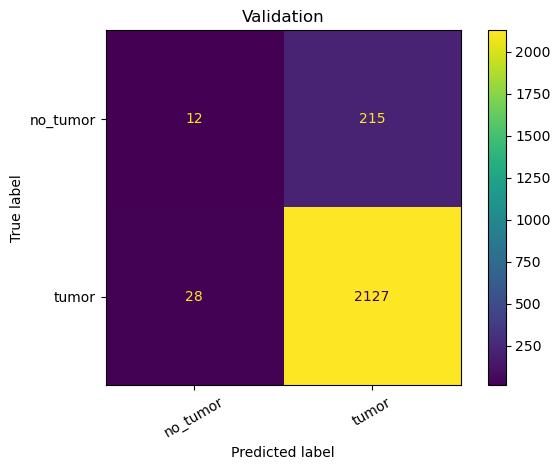

ROC-AUC (positive: tumor ): 0.5110796528920551


In [19]:
def evaluate(part,title):
    actual=y.iloc[part]; pred=model.predict(X.iloc[part]); labels=list(model.classes_)
    print(title,'accuracy',accuracy_score(actual,pred),'balanced accuracy',balanced_accuracy_score(actual,pred),'macro F1',f1_score(actual,pred,average='macro'))
    print(classification_report(actual,pred,zero_division=0))
    ConfusionMatrixDisplay.from_predictions(actual,pred,labels=labels,xticks_rotation=30)
    plt.title(title);plt.tight_layout();plt.show()
    if len(labels)==2:
        positive='tumor' if 'tumor' in labels else labels[1]
        score=model.predict_proba(X.iloc[part])[:,labels.index(positive)]
        print('ROC-AUC (positive:',positive,'):',roc_auc_score((actual==positive).astype(int),score))
evaluate(va,'Validation')
# Uncomment only after all decisions are finalized:
# evaluate(ts,'Held-out test')

## 6. Permutation importance and save model

,feature,mean_drop,std
19,glcm_energy_d1_std,0.013864,0.004458
40,dwt_A2_p10,0.012914,0.002781
41,dwt_A2_p90,0.010224,0.003382
35,glcm_ASM_d4_std,0.010176,0.003342
33,glcm_ASM_d2_std,0.009783,0.002956
23,glcm_energy_d4_std,0.009482,0.002925
47,dwt_H2_p90,0.008484,0.001366
37,dwt_A2_std,0.007929,0.004237
52,dwt_V2_p10,0.007280,0.001158
12,glcm_homogeneity_d1_mean,0.006909,0.001965


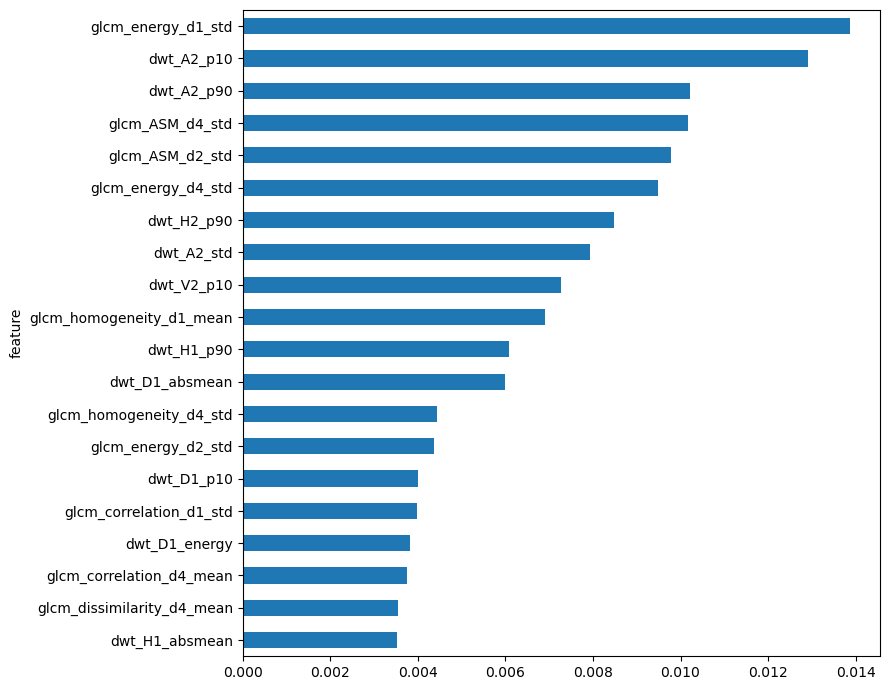

Saved in outputs\model2


In [20]:
r=permutation_importance(model,X.iloc[va],y.iloc[va],scoring='balanced_accuracy',n_repeats=5,random_state=SEED,n_jobs=-1)
imp=pd.DataFrame({'feature':X.columns,'mean_drop':r.importances_mean,'std':r.importances_std}).sort_values('mean_drop',ascending=False)
display(imp.head(20))
imp.head(20).iloc[::-1].plot.barh(x='feature',y='mean_drop',legend=False,figsize=(9,7));plt.tight_layout();plt.show()
joblib.dump({'pipeline':model,'feature_names':list(X.columns),'image_size':IMAGE_SIZE,'classes':list(model.classes_)},OUT/'glcm_wavelet_rf.joblib')
imp.to_csv(OUT/'permutation_importance.csv',index=False)
pd.DataFrame({'image_path':df.image_path,'label':y,'split':np.select([np.isin(idx,tr),np.isin(idx,va)],['train','validation'],default='test')}).to_csv(OUT/'splits.csv',index=False)
print('Saved in',OUT)

## 7. Recommended ablation and reporting

Compare **GLCM-only**, **wavelet-only**, and **GLCM + wavelets** on identical splits, and include a majority-class baseline. Perform any feature selection inside training cross-validation only. Report patient counts, class distribution, dataset provenance, duplicate-image checks, MRI modality and external validation if available. Use patient-level bootstrap confidence intervals if enough independent patients are available. **High MRI classification accuracy does not establish clinical utility.**

**Suggested follow-up:** use segmentation masks only if the selected dataset genuinely supplies them, and compare whole-image versus tumor-region texture features without leaking ground-truth masks into test-time predictions.